# DWML A4: Market Basket Analysis Using Apriori Algorithm
### **Name:** Shreeya Tapaswi
### **Roll No:** 31474
### **Class/Batch:** PICT CE TY 2026-27

---

## 1. Problem Statement
An online bookstore wants to analyze the purchase patterns of its customers. The management believes that certain books are often bought together, and by identifying these associations, they can recommend relevant books, improve cross-selling, and design effective marketing campaigns.

**Objective:** Apply the **Apriori algorithm** to find frequent itemsets with a **minimum support of 40%** (adjusted as per dataset density if needed). From the frequent itemsets, generate **association rules with a minimum confidence of 60%** to discover strong recommendation relationships.

---

## 2. Dataset Description
The dataset used for this analysis is `Market_Basket_Optimisation.csv`, which simulates transaction logs.
- **Type of Data:** Transactional database (market basket format).
- **Attributes:** Each row represents a single customer transaction containing a list of items purchased together.
- **Size:** 7,500 transactions spanning 119 unique items.
- **Preprocessing:** Includes elimination of empty values, removing duplicate transactions, and converting transactions into a structured one-hot encoded binary matrix representing item presence (True/False).

In [54]:
# Install required library
!pip install mlxtend -q

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, association_rules

import warnings
warnings.filterwarnings("ignore")

In [56]:
from google.colab import files

uploaded = files.upload()

Saving Market_Basket_Optimisation.csv to Market_Basket_Optimisation (1).csv


In [57]:
df = pd.read_csv("Market_Basket_Optimisation.csv")

print("Dataset loaded successfully!")
print("\nFirst 10 records:")
display(df.head(10))

Dataset loaded successfully!

First 10 records:


,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
0,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,whole wheat pasta,french fries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,soup,light cream,shallot,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,frozen vegetables,spaghetti,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,french fries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,eggs,pet food,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [58]:
print("Number of transactions:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of transactions: 7500
Number of columns: 20

Column names:
['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   shrimp             7500 non-null   object 
 1   almonds            5746 non-null   object 
 2   avocado            4388 non-null   object 
 3   vegetables mix     3344 non-null   object 
 4   green grapes       2528 non-null   object 
 5   whole weat flour   1863 non-null   object 
 6   yams               1368 non-null   object 
 7   cottage cheese     980 non-null    object 
 8   energy drink       653 non-null    

In [59]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
shrimp                  0
almonds              1754
avocado              3112
vegetables mix       4156
green grapes         4972
whole weat flour     5637
yams                 6132
cottage cheese       6520
energy drink         6847
tomato juice         7106
low fat yogurt       7245
green tea            7347
honey                7414
salad                7454
mineral water        7476
salmon               7493
antioxydant juice    7497
frozen smoothie      7497
spinach              7498
olive oil            7500
dtype: int64


In [60]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentage:")
print(missing_percentage)


Missing value percentage:
shrimp                 0.000000
almonds               23.386667
avocado               41.493333
vegetables mix        55.413333
green grapes          66.293333
whole weat flour      75.160000
yams                  81.760000
cottage cheese        86.933333
energy drink          91.293333
tomato juice          94.746667
low fat yogurt        96.600000
green tea             97.960000
honey                 98.853333
salad                 99.386667
mineral water         99.680000
salmon                99.906667
antioxydant juice     99.960000
frozen smoothie       99.960000
spinach               99.973333
olive oil            100.000000
dtype: float64


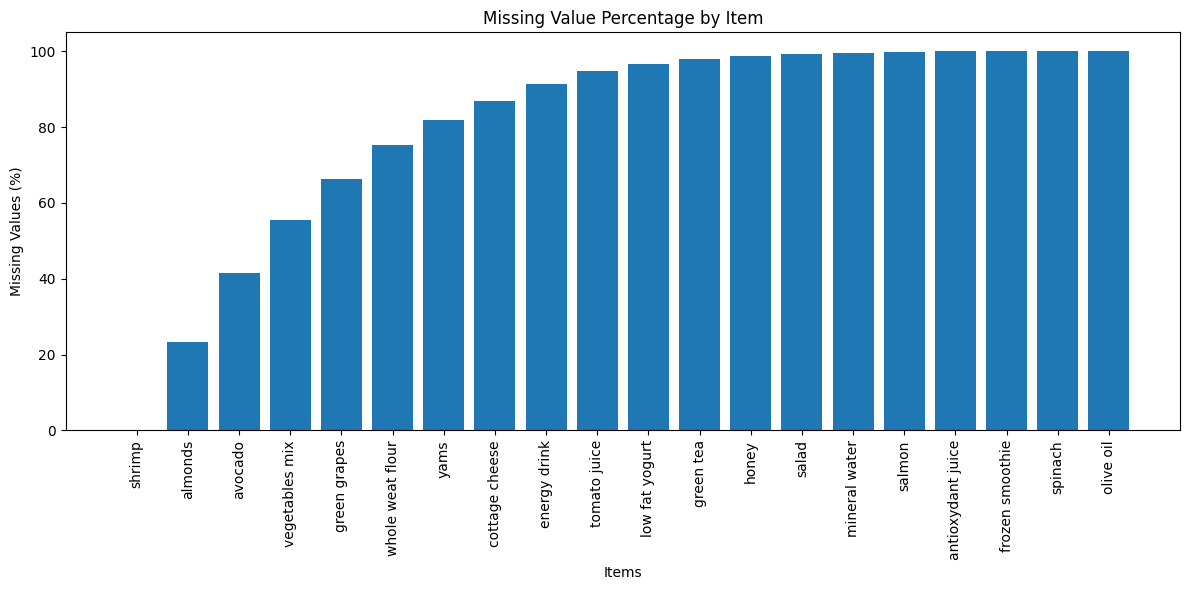

In [61]:
plt.figure(figsize=(12, 6))

plt.bar(
    df.columns,
    missing_percentage
)

plt.xlabel("Items")
plt.ylabel("Missing Values (%)")
plt.title("Missing Value Percentage by Item")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [62]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 2325


In [63]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (5175, 20)


In [64]:
display(df)

,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
0,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,low fat yogurt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7492,burgers,salmon,pancakes,french fries,frozen smoothie,fresh bread,mint,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7493,turkey,burgers,dessert wine,shrimp,pasta,tomatoes,pepper,milk,pancakes,whole wheat rice,oil,frozen smoothie,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7495,butter,light mayo,fresh bread,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7496,burgers,frozen vegetables,eggs,french fries,magazines,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [65]:
transactions = []

for _, row in df.iterrows():
    transaction = [
        item.strip()
        for item in row.dropna()
        if str(item).strip() != ""
    ]

    transactions.append(transaction)

print("First 10 transactions:\n")

for i, transaction in enumerate(transactions[:10], start=1):
    print(f"T{i:04d}: {transaction}")

First 10 transactions:

T0001: ['burgers', 'meatballs', 'eggs']
T0002: ['chutney']
T0003: ['turkey', 'avocado']
T0004: ['mineral water', 'milk', 'energy bar', 'whole wheat rice', 'green tea']
T0005: ['low fat yogurt']
T0006: ['whole wheat pasta', 'french fries']
T0007: ['soup', 'light cream', 'shallot']
T0008: ['frozen vegetables', 'spaghetti', 'green tea']
T0009: ['french fries']
T0010: ['eggs', 'pet food']


In [66]:
all_items = sorted(
    set(
        item
        for transaction in transactions
        for item in transaction
    )
)

print("Total unique items:", len(all_items))

print("\nItems available:")

for i, item in enumerate(all_items, start=1):
    print(i, ".", item)

Total unique items: 119

Items available:
1 . almonds
2 . antioxydant juice
3 . asparagus
4 . avocado
5 . babies food
6 . bacon
7 . barbecue sauce
8 . black tea
9 . blueberries
10 . body spray
11 . bramble
12 . brownies
13 . bug spray
14 . burger sauce
15 . burgers
16 . butter
17 . cake
18 . candy bars
19 . carrots
20 . cauliflower
21 . cereals
22 . champagne
23 . chicken
24 . chili
25 . chocolate
26 . chocolate bread
27 . chutney
28 . cider
29 . clothes accessories
30 . cookies
31 . cooking oil
32 . corn
33 . cottage cheese
34 . cream
35 . dessert wine
36 . eggplant
37 . eggs
38 . energy bar
39 . energy drink
40 . escalope
41 . extra dark chocolate
42 . flax seed
43 . french fries
44 . french wine
45 . fresh bread
46 . fresh tuna
47 . fromage blanc
48 . frozen smoothie
49 . frozen vegetables
50 . gluten free bar
51 . grated cheese
52 . green beans
53 . green grapes
54 . green tea
55 . ground beef
56 . gums
57 . ham
58 . hand protein bar
59 . herb & pepper
60 . honey
61 . hot dogs
62 .

In [67]:
item_counts = {}

for transaction in transactions:
    for item in transaction:
        item_counts[item] = item_counts.get(item, 0) + 1

item_frequency = pd.DataFrame(
    list(item_counts.items()),
    columns=["Item", "Transaction_Count"]
)

item_frequency = item_frequency.sort_values(
    by="Transaction_Count",
    ascending=False
).reset_index(drop=True)

display(item_frequency)

,Item,Transaction_Count
0,mineral water,1551
1,spaghetti,1188
2,eggs,1077
3,chocolate,1063
4,french fries,997
...,...,...
114,sandwich,28
115,bramble,13
116,cream,7
117,napkins,5


In [68]:
item_frequency["Support"] = (
    item_frequency["Transaction_Count"] / len(df)
)

item_frequency["Support_Percentage"] = (
    item_frequency["Support"] * 100
)

display(item_frequency)

,Item,Transaction_Count,Support,Support_Percentage
0,mineral water,1551,0.299710,29.971014
1,spaghetti,1188,0.229565,22.956522
2,eggs,1077,0.208116,20.811594
3,chocolate,1063,0.205411,20.541063
4,french fries,997,0.192657,19.265700
...,...,...,...,...
114,sandwich,28,0.005411,0.541063
115,bramble,13,0.002512,0.251208
116,cream,7,0.001353,0.135266
117,napkins,5,0.000966,0.096618


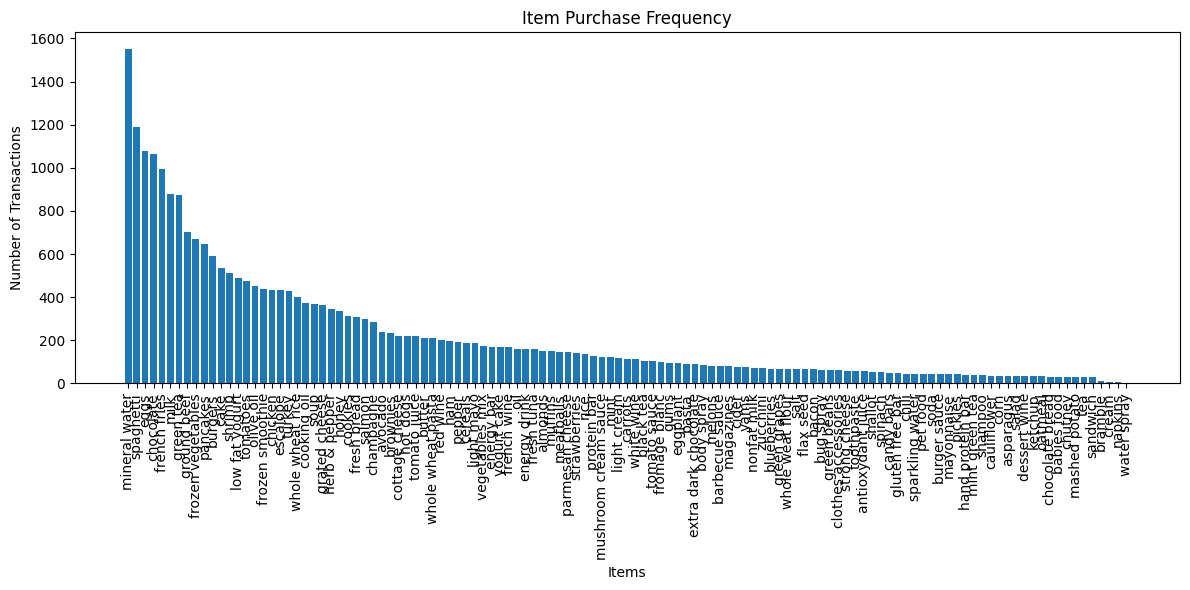

In [69]:
plt.figure(figsize=(12, 6))

plt.bar(
    item_frequency["Item"],
    item_frequency["Transaction_Count"]
)

plt.xlabel("Items")
plt.ylabel("Number of Transactions")
plt.title("Item Purchase Frequency")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

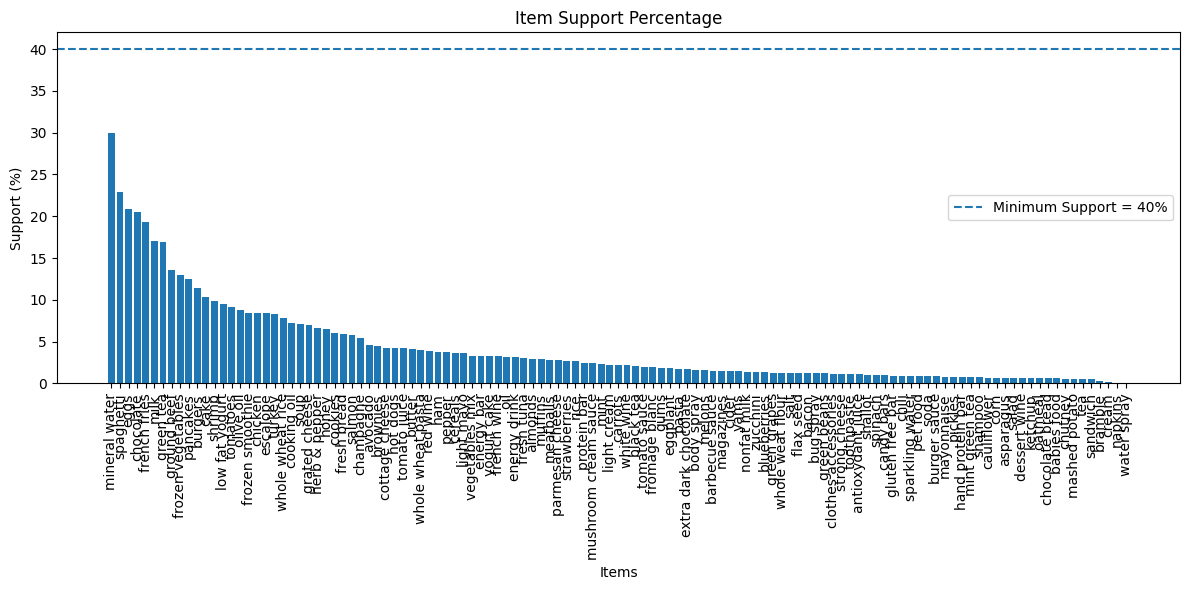

In [70]:
plt.figure(figsize=(12, 6))

plt.bar(
    item_frequency["Item"],
    item_frequency["Support_Percentage"]
)

plt.axhline(
    y=40,
    linestyle="--",
    label="Minimum Support = 40%"
)

plt.xlabel("Items")
plt.ylabel("Support (%)")
plt.title("Item Support Percentage")

plt.xticks(rotation=90)

plt.legend()

plt.tight_layout()
plt.show()

In [71]:
basket = pd.DataFrame(
    0,
    index=range(len(transactions)),
    columns=all_items
)

for transaction_id, items in enumerate(transactions):
    for item in items:
        basket.loc[transaction_id, item] = 1

basket.index.name = "TransactionID"

display(basket.head(10))

,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
TransactionID,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [72]:
print("Basket shape:", basket.shape)

print("\nUnique values:")

for column in basket.columns:
    print(column, ":", basket[column].unique())

Basket shape: (5175, 119)

Unique values:
almonds : [0 1]
antioxydant juice : [0 1]
asparagus : [0 1]
avocado : [0 1]
babies food : [0 1]
bacon : [0 1]
barbecue sauce : [0 1]
black tea : [0 1]
blueberries : [0 1]
body spray : [0 1]
bramble : [0 1]
brownies : [0 1]
bug spray : [0 1]
burger sauce : [0 1]
burgers : [1 0]
butter : [0 1]
cake : [0 1]
candy bars : [0 1]
carrots : [0 1]
cauliflower : [0 1]
cereals : [0 1]
champagne : [0 1]
chicken : [0 1]
chili : [0 1]
chocolate : [0 1]
chocolate bread : [0 1]
chutney : [0 1]
cider : [0 1]
clothes accessories : [0 1]
cookies : [0 1]
cooking oil : [0 1]
corn : [0 1]
cottage cheese : [0 1]
cream : [0 1]
dessert wine : [0 1]
eggplant : [0 1]
eggs : [1 0]
energy bar : [0 1]
energy drink : [0 1]
escalope : [0 1]
extra dark chocolate : [0 1]
flax seed : [0 1]
french fries : [0 1]
french wine : [0 1]
fresh bread : [0 1]
fresh tuna : [0 1]
fromage blanc : [0 1]
frozen smoothie : [0 1]
frozen vegetables : [0 1]
gluten free bar : [0 1]
grated cheese : 

In [73]:
basket = basket.astype(bool)

display(basket.head(10))

,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
TransactionID,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
6,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [74]:
# min_support = 0.40
min_support = 0.01

In [75]:
min_support = 0.01

print("Minimum Support:", min_support * 100, "%")

Minimum Support: 1.0 %


In [76]:
frequent_itemsets = apriori(
    basket,
    min_support=min_support,
    use_colnames=True
)

print("Frequent itemsets found:", len(frequent_itemsets))

display(frequent_itemsets)

Frequent itemsets found: 436


,support,itemsets
0,0.029179,(almonds)
1,0.011014,(antioxydant juice)
2,0.045797,(avocado)
3,0.012560,(bacon)
4,0.015459,(barbecue sauce)
...,...,...
431,0.014686,"(olive oil, mineral water, spaghetti)"
432,0.016618,"(pancakes, mineral water, spaghetti)"
433,0.012367,"(spaghetti, mineral water, shrimp)"
434,0.010821,"(mineral water, soup, spaghetti)"


In [77]:
frequent_itemsets["Support_Percentage"] = (
    frequent_itemsets["support"] * 100
)

display(frequent_itemsets)

,support,itemsets,Support_Percentage
0,0.029179,(almonds),2.917874
1,0.011014,(antioxydant juice),1.101449
2,0.045797,(avocado),4.579710
3,0.012560,(bacon),1.256039
4,0.015459,(barbecue sauce),1.545894
...,...,...,...
431,0.014686,"(olive oil, mineral water, spaghetti)",1.468599
432,0.016618,"(pancakes, mineral water, spaghetti)",1.661836
433,0.012367,"(spaghetti, mineral water, shrimp)",1.236715
434,0.010821,"(mineral water, soup, spaghetti)",1.082126


In [78]:
frequent_itemsets["Itemset_Size"] = (
    frequent_itemsets["itemsets"].apply(len)
)

display(
    frequent_itemsets[
        [
            "itemsets",
            "Itemset_Size",
            "support",
            "Support_Percentage"
        ]
    ]
)

,itemsets,Itemset_Size,support,Support_Percentage
0,(almonds),1,0.029179,2.917874
1,(antioxydant juice),1,0.011014,1.101449
2,(avocado),1,0.045797,4.579710
3,(bacon),1,0.012560,1.256039
4,(barbecue sauce),1,0.015459,1.545894
...,...,...,...,...
431,"(olive oil, mineral water, spaghetti)",3,0.014686,1.468599
432,"(pancakes, mineral water, spaghetti)",3,0.016618,1.661836
433,"(spaghetti, mineral water, shrimp)",3,0.012367,1.236715
434,"(mineral water, soup, spaghetti)",3,0.010821,1.082126


In [79]:
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

display(frequent_itemsets)

,support,itemsets,Support_Percentage,Itemset_Size
0,0.299710,(mineral water),29.971014,1
1,0.229565,(spaghetti),22.956522,1
2,0.208116,(eggs),20.811594,1
3,0.205217,(chocolate),20.521739,1
4,0.192657,(french fries),19.265700,1
...,...,...,...,...
431,0.010048,"(spaghetti, cottage cheese)",1.004831,2
432,0.010048,"(burgers, milk, mineral water)",1.004831,3
433,0.010048,"(chicken, mineral water, spaghetti)",1.004831,3
434,0.010048,"(green tea, chocolate, mineral water)",1.004831,3


In [80]:
print(
    f"FREQUENT ITEMSETS "
    f"(Minimum Support = {min_support * 100:.0f}%)"
)

print("=" * 70)

for _, row in frequent_itemsets.iterrows():

    items = ", ".join(sorted(row["itemsets"]))

    print(
        f"{{{items}}}  -->  "
        f"Support = {row['Support_Percentage']:.2f}%"
    )

FREQUENT ITEMSETS (Minimum Support = 1%)
{mineral water}  -->  Support = 29.97%
{spaghetti}  -->  Support = 22.96%
{eggs}  -->  Support = 20.81%
{chocolate}  -->  Support = 20.52%
{french fries}  -->  Support = 19.27%
{milk}  -->  Support = 17.00%
{green tea}  -->  Support = 16.91%
{ground beef}  -->  Support = 13.58%
{frozen vegetables}  -->  Support = 12.99%
{pancakes}  -->  Support = 12.52%
{burgers}  -->  Support = 11.38%
{cake}  -->  Support = 10.36%
{shrimp}  -->  Support = 9.87%
{low fat yogurt}  -->  Support = 9.49%
{tomatoes}  -->  Support = 9.20%
{olive oil}  -->  Support = 8.75%
{mineral water, spaghetti}  -->  Support = 8.50%
{frozen smoothie}  -->  Support = 8.46%
{escalope}  -->  Support = 8.39%
{chicken}  -->  Support = 8.39%
{turkey}  -->  Support = 8.33%
{whole wheat rice}  -->  Support = 7.79%
{chocolate, mineral water}  -->  Support = 7.32%
{cooking oil}  -->  Support = 7.19%
{soup}  -->  Support = 7.09%
{grated cheese}  -->  Support = 7.01%
{eggs, mineral water}  --

In [81]:
one_itemsets = frequent_itemsets[
    frequent_itemsets["Itemset_Size"] == 1
]

print("Frequent 1-Itemsets:")

display(one_itemsets)

Frequent 1-Itemsets:


,support,itemsets,Support_Percentage,Itemset_Size
0,0.299710,(mineral water),29.971014,1
1,0.229565,(spaghetti),22.956522,1
2,0.208116,(eggs),20.811594,1
3,0.205217,(chocolate),20.521739,1
4,0.192657,(french fries),19.265700,1
...,...,...,...,...
341,0.011787,(clothes accessories),1.178744,1
362,0.011208,(strong cheese),1.120773,1
363,0.011208,(toothpaste),1.120773,1
380,0.011014,(antioxydant juice),1.101449,1


In [82]:
two_itemsets = frequent_itemsets[
    frequent_itemsets["Itemset_Size"] == 2
]

print("Frequent 2-Itemsets:")

display(two_itemsets)

Frequent 2-Itemsets:


,support,itemsets,Support_Percentage,Itemset_Size
16,0.085024,"(mineral water, spaghetti)",8.502415,2
22,0.073237,"(chocolate, mineral water)",7.323671,2
26,0.070145,"(mineral water, eggs)",7.014493,2
27,0.067826,"(milk, mineral water)",6.782609,2
32,0.058744,"(mineral water, ground beef)",5.874396,2
...,...,...,...,...
428,0.010048,"(whole wheat rice, pancakes)",1.004831,2
429,0.010048,"(soup, tomatoes)",1.004831,2
430,0.010048,"(french fries, herb & pepper)",1.004831,2
431,0.010048,"(spaghetti, cottage cheese)",1.004831,2


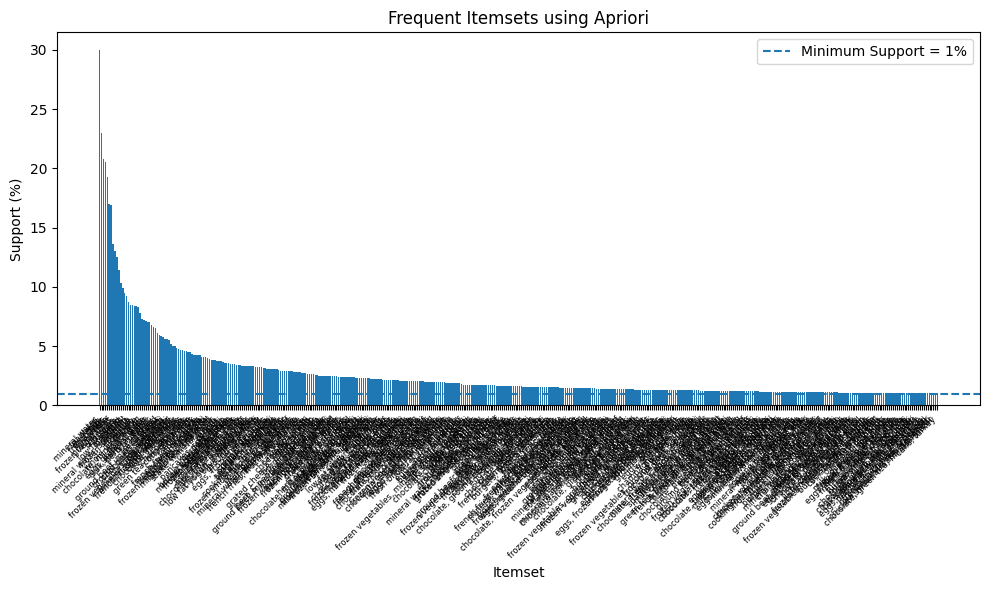

In [83]:
itemset_labels = [
    ", ".join(sorted(itemset))
    for itemset in frequent_itemsets["itemsets"]
]

support_values = frequent_itemsets["Support_Percentage"]

plt.figure(figsize=(10, 6))

plt.bar(
    itemset_labels,
    support_values
)

plt.axhline(
    y=min_support * 100,
    linestyle="--",
    label=f"Minimum Support = {min_support * 100:.0f}%"
)

plt.xlabel("Itemset")
plt.ylabel("Support (%)")
plt.title("Frequent Itemsets using Apriori")
plt.xticks(rotation=90)
plt.xticks(
    rotation=45,
    ha="right",
    fontsize=6
)

plt.legend()

plt.tight_layout()

plt.show()

In [84]:
min_confidence = 0.30

print("Minimum Confidence:", min_confidence * 100, "%")

Minimum Confidence: 30.0 %


In [85]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=min_confidence
)

print("Number of association rules:", len(rules))

display(rules)

Number of association rules: 150


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(spaghetti),(mineral water),0.229565,0.299710,0.085024,0.370370,1.235762,1.0,0.016221,1.112225,0.247630,0.191388,0.100901,0.327029
1,(chocolate),(mineral water),0.205217,0.299710,0.073237,0.356874,1.190730,1.0,0.011731,1.088884,0.201538,0.169651,0.081629,0.300616
2,(eggs),(mineral water),0.208116,0.299710,0.070145,0.337047,1.124578,1.0,0.007770,1.056320,0.139891,0.160265,0.053317,0.285545
3,(milk),(mineral water),0.170048,0.299710,0.067826,0.398864,1.330831,1.0,0.016861,1.164943,0.299523,0.168750,0.141589,0.312585
4,(ground beef),(mineral water),0.135845,0.299710,0.058744,0.432432,1.442835,1.0,0.018030,1.233844,0.355168,0.155897,0.189525,0.314218
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,"(cake, eggs)",(mineral water),0.026667,0.299710,0.010242,0.384058,1.281431,1.0,0.002249,1.136941,0.225640,0.032396,0.120447,0.209115
146,"(cake, spaghetti)",(mineral water),0.026280,0.299710,0.010242,0.389706,1.300276,1.0,0.002365,1.147463,0.237165,0.032436,0.128512,0.211939
147,"(burgers, milk)",(mineral water),0.025507,0.299710,0.010048,0.393939,1.314401,1.0,0.002404,1.155478,0.245458,0.031882,0.134557,0.213733
148,"(chicken, mineral water)",(spaghetti),0.032657,0.229565,0.010048,0.307692,1.340326,1.0,0.002551,1.112850,0.262485,0.039847,0.101406,0.175732


In [86]:
rules_result = rules[
    [
        "antecedents",
        "consequents",
        "support",
        "confidence",
        "lift"
    ]
].copy()

display(rules_result)

,antecedents,consequents,support,confidence,lift
0,(spaghetti),(mineral water),0.085024,0.370370,1.235762
1,(chocolate),(mineral water),0.073237,0.356874,1.190730
2,(eggs),(mineral water),0.070145,0.337047,1.124578
3,(milk),(mineral water),0.067826,0.398864,1.330831
4,(ground beef),(mineral water),0.058744,0.432432,1.442835
...,...,...,...,...,...
145,"(cake, eggs)",(mineral water),0.010242,0.384058,1.281431
146,"(cake, spaghetti)",(mineral water),0.010242,0.389706,1.300276
147,"(burgers, milk)",(mineral water),0.010048,0.393939,1.314401
148,"(chicken, mineral water)",(spaghetti),0.010048,0.307692,1.340326


In [87]:
rules_result["support"] = (
    rules_result["support"] * 100
)

rules_result["confidence"] = (
    rules_result["confidence"] * 100
)

display(rules_result)

,antecedents,consequents,support,confidence,lift
0,(spaghetti),(mineral water),8.502415,37.037037,1.235762
1,(chocolate),(mineral water),7.323671,35.687382,1.190730
2,(eggs),(mineral water),7.014493,33.704735,1.124578
3,(milk),(mineral water),6.782609,39.886364,1.330831
4,(ground beef),(mineral water),5.874396,43.243243,1.442835
...,...,...,...,...,...
145,"(cake, eggs)",(mineral water),1.024155,38.405797,1.281431
146,"(cake, spaghetti)",(mineral water),1.024155,38.970588,1.300276
147,"(burgers, milk)",(mineral water),1.004831,39.393939,1.314401
148,"(chicken, mineral water)",(spaghetti),1.004831,30.769231,1.340326


In [88]:
readable_rules = []

for _, row in rules.iterrows():

    antecedent = ", ".join(
        sorted(row["antecedents"])
    )

    consequent = ", ".join(
        sorted(row["consequents"])
    )

    readable_rules.append({
        "Rule": f"{antecedent} -> {consequent}",
        "Support (%)": row["support"] * 100,
        "Confidence (%)": row["confidence"] * 100,
        "Lift": row["lift"]
    })

rules_df = pd.DataFrame(readable_rules)

display(rules_df)

,Rule,Support (%),Confidence (%),Lift
0,spaghetti -> mineral water,8.502415,37.037037,1.235762
1,chocolate -> mineral water,7.323671,35.687382,1.190730
2,eggs -> mineral water,7.014493,33.704735,1.124578
3,milk -> mineral water,6.782609,39.886364,1.330831
4,ground beef -> mineral water,5.874396,43.243243,1.442835
...,...,...,...,...
145,"cake, eggs -> mineral water",1.024155,38.405797,1.281431
146,"cake, spaghetti -> mineral water",1.024155,38.970588,1.300276
147,"burgers, milk -> mineral water",1.004831,39.393939,1.314401
148,"chicken, mineral water -> spaghetti",1.004831,30.769231,1.340326


In [89]:
strong_rules = rules_df[
    rules_df["Confidence (%)"] >= min_confidence * 100
].copy()

strong_rules = strong_rules.sort_values(
    by="Confidence (%)",
    ascending=False
)

print("Strong Association Rules:")

display(strong_rules)

Strong Association Rules:


,Rule,Support (%),Confidence (%),Lift
91,"milk, soup -> mineral water",1.236715,57.657658,1.923781
82,"frozen vegetables, ground beef -> mineral water",1.333333,54.330709,1.812775
128,"soup, spaghetti -> mineral water",1.082126,52.336449,1.746235
130,"ground beef, pancakes -> mineral water",1.082126,51.851852,1.730067
118,"chicken, chocolate -> mineral water",1.101449,51.818182,1.728943
...,...,...,...,...
39,soup -> milk,2.144928,30.245232,1.778626
104,"frozen vegetables, spaghetti -> milk",1.178744,30.198020,1.775849
26,turkey -> eggs,2.512077,30.162413,1.449308
144,"chocolate, green tea -> spaghetti",1.024155,30.113636,1.311768


In [90]:
rules_by_confidence = rules_df.sort_values(
    by="Confidence (%)",
    ascending=False
)

display(rules_by_confidence)

,Rule,Support (%),Confidence (%),Lift
91,"milk, soup -> mineral water",1.236715,57.657658,1.923781
82,"frozen vegetables, ground beef -> mineral water",1.333333,54.330709,1.812775
128,"soup, spaghetti -> mineral water",1.082126,52.336449,1.746235
130,"ground beef, pancakes -> mineral water",1.082126,51.851852,1.730067
118,"chicken, chocolate -> mineral water",1.101449,51.818182,1.728943
...,...,...,...,...
39,soup -> milk,2.144928,30.245232,1.778626
104,"frozen vegetables, spaghetti -> milk",1.178744,30.198020,1.775849
26,turkey -> eggs,2.512077,30.162413,1.449308
144,"chocolate, green tea -> spaghetti",1.024155,30.113636,1.311768


In [91]:
rules_by_lift = rules_df.sort_values(
    by="Lift",
    ascending=False
)

display(rules_by_lift)

,Rule,Support (%),Confidence (%),Lift
35,herb & pepper -> ground beef,2.280193,34.302326,2.525100
137,"mineral water, shrimp -> frozen vegetables",1.043478,31.213873,2.403747
87,"frozen vegetables, spaghetti -> ground beef",1.256039,32.178218,2.368738
88,"frozen vegetables, ground beef -> spaghetti",1.256039,51.181102,2.229480
92,"mineral water, soup -> milk",1.236715,36.994220,2.175512
...,...,...,...,...
81,hot dogs -> mineral water,1.333333,31.363636,1.046466
97,"green tea, spaghetti -> mineral water",1.198068,31.155779,1.039530
69,brownies -> mineral water,1.391304,30.901288,1.031039
126,"burgers, eggs -> mineral water",1.101449,30.481283,1.017025


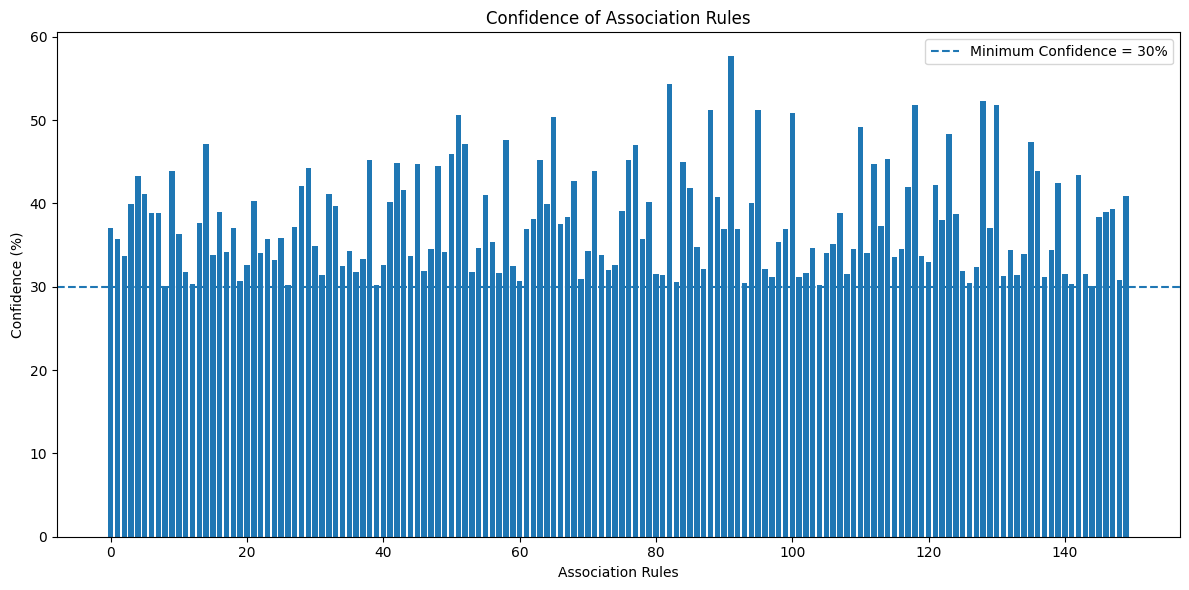

In [92]:
plt.figure(figsize=(12, 6))

plt.bar(
    range(len(rules_df)),
    rules_df["Confidence (%)"]
)

plt.axhline(
    y=min_confidence * 100,
    linestyle="--",
    label=f"Minimum Confidence = {min_confidence * 100:.0f}%"
)

plt.xlabel("Association Rules")
plt.ylabel("Confidence (%)")
plt.title("Confidence of Association Rules")

plt.legend()

plt.tight_layout()
plt.show()

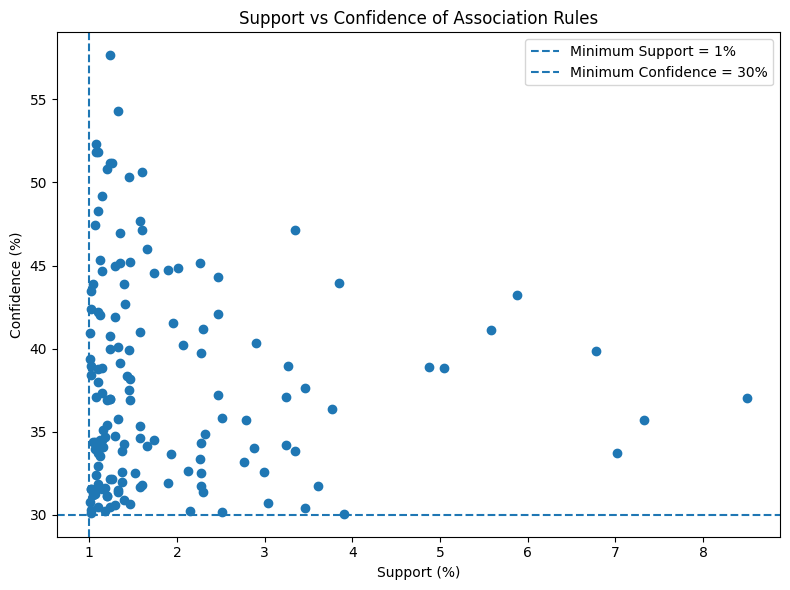

In [93]:
plt.figure(figsize=(8, 6))

plt.scatter(
    rules_df["Support (%)"],
    rules_df["Confidence (%)"]
)

plt.xlabel("Support (%)")
plt.ylabel("Confidence (%)")

plt.title("Support vs Confidence of Association Rules")

plt.axvline(
    x=min_support * 100,
    linestyle="--",
    label=f"Minimum Support = {min_support * 100:.0f}%"
)

plt.axhline(
    y=min_confidence * 100,
    linestyle="--",
    label=f"Minimum Confidence = {min_confidence * 100:.0f}%"
)

plt.legend()

plt.tight_layout()

plt.show()

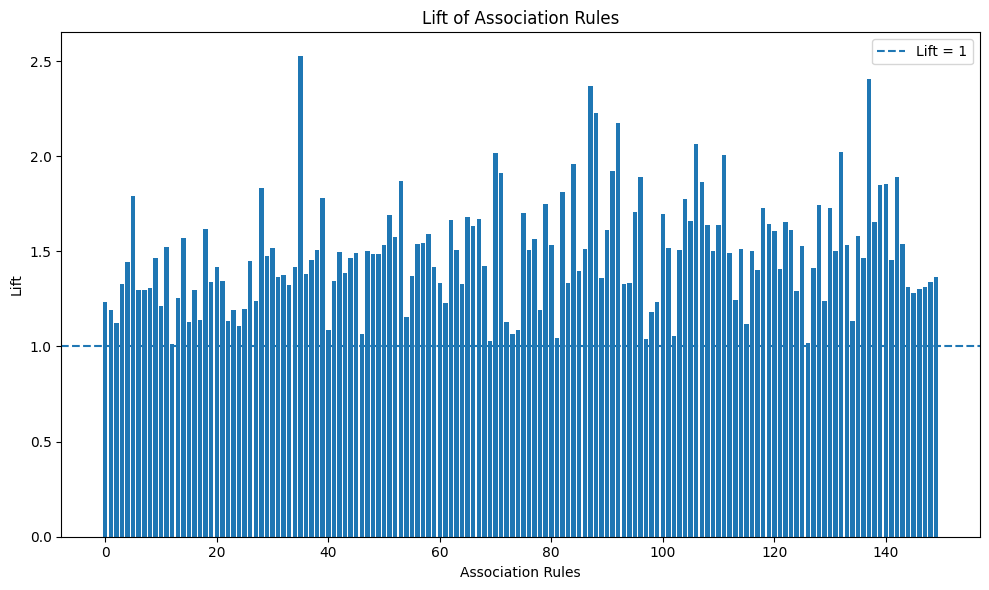

In [94]:
plt.figure(figsize=(10, 6))

plt.bar(
    range(len(rules_df)),
    rules_df["Lift"]
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Lift = 1"
)

plt.xlabel("Association Rules")
plt.ylabel("Lift")
plt.title("Lift of Association Rules")

plt.legend()

plt.tight_layout()
plt.show()

In [95]:
print("FINAL ASSOCIATION RULES")

print("=" * 80)

for _, row in rules_df.iterrows():

    print(f"\nRule: {row['Rule']}")

    print(
        f"Support: "
        f"{row['Support (%)']:.2f}%"
    )

    print(
        f"Confidence: "
        f"{row['Confidence (%)']:.2f}%"
    )

    print(
        f"Lift: "
        f"{row['Lift']:.2f}"
    )

FINAL ASSOCIATION RULES

Rule: spaghetti -> mineral water
Support: 8.50%
Confidence: 37.04%
Lift: 1.24

Rule: chocolate -> mineral water
Support: 7.32%
Confidence: 35.69%
Lift: 1.19

Rule: eggs -> mineral water
Support: 7.01%
Confidence: 33.70%
Lift: 1.12

Rule: milk -> mineral water
Support: 6.78%
Confidence: 39.89%
Lift: 1.33

Rule: ground beef -> mineral water
Support: 5.87%
Confidence: 43.24%
Lift: 1.44

Rule: ground beef -> spaghetti
Support: 5.58%
Confidence: 41.11%
Lift: 1.79

Rule: frozen vegetables -> mineral water
Support: 5.04%
Confidence: 38.84%
Lift: 1.30

Rule: pancakes -> mineral water
Support: 4.87%
Confidence: 38.89%
Lift: 1.30

Rule: frozen vegetables -> spaghetti
Support: 3.90%
Confidence: 30.06%
Lift: 1.31

Rule: olive oil -> mineral water
Support: 3.85%
Confidence: 43.93%
Lift: 1.47

Rule: cake -> mineral water
Support: 3.77%
Confidence: 36.38%
Lift: 1.21

Rule: burgers -> eggs
Support: 3.61%
Confidence: 31.75%
Lift: 1.53

Rule: burgers -> mineral water
Support: 3.

In [96]:
if len(rules_df) > 0:

    strongest_rule = rules_df.loc[
        rules_df["Confidence (%)"].idxmax()
    ]

    print("STRONGEST RULE BASED ON CONFIDENCE")

    print("=" * 50)

    print("Rule:", strongest_rule["Rule"])

    print(
        "Support:",
        f"{strongest_rule['Support (%)']:.2f}%"
    )

    print(
        "Confidence:",
        f"{strongest_rule['Confidence (%)']:.2f}%"
    )

    print(
        "Lift:",
        f"{strongest_rule['Lift']:.2f}"
    )

else:

    print("No association rules were generated.")

STRONGEST RULE BASED ON CONFIDENCE
Rule: milk, soup -> mineral water
Support: 1.24%
Confidence: 57.66%
Lift: 1.92


In [97]:
if len(rules_df) > 0:

    highest_lift_rule = rules_df.loc[
        rules_df["Lift"].idxmax()
    ]

    print("RULE WITH HIGHEST LIFT")

    print("=" * 50)

    print("Rule:", highest_lift_rule["Rule"])

    print(
        "Support:",
        f"{highest_lift_rule['Support (%)']:.2f}%"
    )

    print(
        "Confidence:",
        f"{highest_lift_rule['Confidence (%)']:.2f}%"
    )

    print(
        "Lift:",
        f"{highest_lift_rule['Lift']:.2f}"
    )

else:

    print("No association rules were generated.")

RULE WITH HIGHEST LIFT
Rule: herb & pepper -> ground beef
Support: 2.28%
Confidence: 34.30%
Lift: 2.53


In [98]:
print("SHOPPING RECOMMENDATION INSIGHTS")

print("=" * 70)

if len(rules_df) > 0:

    for _, row in rules_df.iterrows():

        antecedent = row["Rule"].split(" -> ")[0]
        consequent = row["Rule"].split(" -> ")[1]

        print(
            f"If a customer purchases "
            f"{antecedent}, recommend "
            f"{consequent}."
        )

        print(
            f"Confidence: "
            f"{row['Confidence (%)']:.2f}% | "
            f"Lift: {row['Lift']:.2f}"
        )

        print()

else:

    print("No recommendation rules were generated.")

SHOPPING RECOMMENDATION INSIGHTS
If a customer purchases spaghetti, recommend mineral water.
Confidence: 37.04% | Lift: 1.24

If a customer purchases chocolate, recommend mineral water.
Confidence: 35.69% | Lift: 1.19

If a customer purchases eggs, recommend mineral water.
Confidence: 33.70% | Lift: 1.12

If a customer purchases milk, recommend mineral water.
Confidence: 39.89% | Lift: 1.33

If a customer purchases ground beef, recommend mineral water.
Confidence: 43.24% | Lift: 1.44

If a customer purchases ground beef, recommend spaghetti.
Confidence: 41.11% | Lift: 1.79

If a customer purchases frozen vegetables, recommend mineral water.
Confidence: 38.84% | Lift: 1.30

If a customer purchases pancakes, recommend mineral water.
Confidence: 38.89% | Lift: 1.30

If a customer purchases frozen vegetables, recommend spaghetti.
Confidence: 30.06% | Lift: 1.31

If a customer purchases olive oil, recommend mineral water.
Confidence: 43.93% | Lift: 1.47

If a customer purchases cake, recomm

In [99]:
frequent_itemsets.to_csv(
    "frequent_itemsets.csv",
    index=False
)

rules_df.to_csv(
    "association_rules.csv",
    index=False
)

item_frequency.to_csv(
    "item_frequency.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [100]:
import pandas as pd

# Recreate item_frequency from the transactions
if 'transactions' in globals():
    item_counts = {}
    for transaction in transactions:
        for item in transaction:
            item_counts[item] = item_counts.get(item, 0) + 1
    item_frequency = pd.DataFrame(list(item_counts.items()), columns=["Item", "Transaction_Count"])
    item_frequency = item_frequency.sort_values(by="Transaction_Count", ascending=False).reset_index(drop=True)
    item_frequency["Support"] = item_frequency["Transaction_Count"] / len(df)
    item_frequency["Support_Percentage"] = item_frequency["Support"] * 100

# Recreate rules_df from the association rules output
if 'rules' in globals():
    readable_rules = []
    for _, row in rules.iterrows():
        antecedent = ", ".join(sorted(row["antecedents"]))
        consequent = ", ".join(sorted(row["consequents"]))
        readable_rules.append({
            "Rule": f"{antecedent} -> {consequent}",
            "Support (%)": row["support"] * 100,
            "Confidence (%)": row["confidence"] * 100,
            "Lift": row["lift"]
        })
    rules_df = pd.DataFrame(readable_rules)

print("Successfully reconstructed 'rules_df' and 'item_frequency' variables!")

Successfully reconstructed 'rules_df' and 'item_frequency' variables!


In [101]:
print("=== Association Rules ===")
display(rules_df.head(20))

=== Association Rules ===


,Rule,Support (%),Confidence (%),Lift
0,spaghetti -> mineral water,8.502415,37.037037,1.235762
1,chocolate -> mineral water,7.323671,35.687382,1.190730
2,eggs -> mineral water,7.014493,33.704735,1.124578
3,milk -> mineral water,6.782609,39.886364,1.330831
4,ground beef -> mineral water,5.874396,43.243243,1.442835
5,ground beef -> spaghetti,5.584541,41.109531,1.790756
6,frozen vegetables -> mineral water,5.043478,38.839286,1.295895
7,pancakes -> mineral water,4.869565,38.888889,1.297550
8,frozen vegetables -> spaghetti,3.903382,30.059524,1.309411
9,olive oil -> mineral water,3.845411,43.929360,1.465728


In [102]:
print("=== Item Frequency ===")
display(item_frequency.head(20))

=== Item Frequency ===


,Item,Transaction_Count,Support,Support_Percentage
0,mineral water,1551,0.299710,29.971014
1,spaghetti,1188,0.229565,22.956522
2,eggs,1077,0.208116,20.811594
3,chocolate,1063,0.205411,20.541063
4,french fries,997,0.192657,19.265700
5,milk,880,0.170048,17.004831
6,green tea,875,0.169082,16.908213
7,ground beef,703,0.135845,13.584541
8,frozen vegetables,672,0.129855,12.985507
9,pancakes,648,0.125217,12.521739


## Conclusion

The Apriori algorithm was successfully applied to the Market Basket Optimisation dataset to identify frequently purchased items and meaningful association rules.

The transaction data was preprocessed by handling missing values, identifying and removing duplicate transactions, and converting the transaction records into a Boolean basket representation suitable for association-rule mining.

Frequent itemsets were identified using the selected minimum support threshold. Association rules were then generated using the minimum confidence threshold, and their strength was evaluated using support, confidence, and lift.

The discovered relationships can help retailers understand customer purchasing behaviour, recommend related products, create product bundles, improve cross-selling, and support targeted marketing strategies.

Therefore, the Apriori algorithm is an effective data-mining technique for discovering purchasing patterns and extracting useful business insights from market basket transaction data.